# Demo: Tìm hiểu mô hình ngôn ngữ lớn (LLMs)

Notebook minh họa các cơ chế cốt lõi của Mô hình Ngôn ngữ Lớn (LLMs) theo các mục từ 2 đến 10 của đề bài thông qua thực nghiệm và trực quan hóa dữ liệu.

**Phân định thành phần thực nghiệm:**

| Thành phần | Đặc điểm kỹ thuật | Mục tiêu khảo sát |
|---|---|---|
| **Tokenizer (GPT-2, Llama 2)** | BPE byte-level (50.257 token) và SentencePiece BPE (32.000 token) | Phân tích subword, token ID và độ giãn nở ngữ cảnh tiếng Việt vs tiếng Anh (Mục 3, 9) |
| **Mô hình MiniGPT** | Transformer decoder-only (~0,8M tham số), mức ký tự | Quan sát cơ chế causal attention, hàm mất mát cross-entropy và các tham số giải mã ($T$, top-$p$, greedy) (Mục 2, 4, 6, 9, 10) |
| **Mô hình LLM (Qwen 2.5 7B)** | Mô hình chỉ dẫn quy mô lớn | Đánh giá năng lực in-context learning qua so sánh zero-shot và few-shot (Mục 7, 10) |


In [ ]:
import sys, os, re, json, math
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src")); sys.path.insert(0, str(ROOT))

import numpy as np, pandas as pd, torch, torch.nn.functional as F
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from IPython.display import display, Markdown

torch.set_num_threads(1); torch.manual_seed(0); np.random.seed(0)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
pd.set_option("display.max_colwidth", 80); pd.set_option("display.width", 160)

from minigpt import CharTokenizer, MiniGPT, generate, adjust_probs
import tok_utils
import run_llm_experiment as rle

corpus = open("data/tinyshakespeare.txt", encoding="utf-8").read()
tok = CharTokenizer(corpus)
ckpt = torch.load("checkpoints/minigpt.pt", map_location="cpu")
assert tok.chars == ckpt["chars"]
model = MiniGPT(**ckpt["cfg"]); model.load_state_dict(ckpt["state"]); model.eval()
hist = json.load(open("results/train_history.json"))
print(f"MiniGPT: {model.n_params():,} tham số | từ vựng {tok.vocab_size} ký tự | cửa sổ ngữ cảnh {model.block_size} | "
      f"{ckpt['cfg']['n_layer']} khối, {ckpt['cfg']['n_head']} head, d={ckpt['cfg']['n_embd']}")
print(f"Sau {hist['steps']} bước: train loss {hist['history'][-1]['train_loss']:.3f}, val loss {hist['history'][-1]['val_loss']:.3f}")

MiniGPT: 818,048 tham số | từ vựng 65 ký tự | cửa sổ ngữ cảnh 128 | 4 khối, 4 head, d=128
Sau 2500 bước: train loss 1.383, val loss 1.579


## Mục 2 – Nền tảng kiến trúc: decoder-only và causal attention

Ba thứ cần chứng minh bằng chạy thật:
1. **Mặt nạ nhân quả**: trọng số attention của vị trí *t* với các vị trí *> t* bằng 0.
2. **Tính nhân quả**: đổi các token ở tương lai **không** làm thay đổi đầu ra tại các vị trí trước đó.
3. **Luồng dữ liệu** từ token đầu vào đến xác suất token tiếp theo, với kích thước tensor thật.

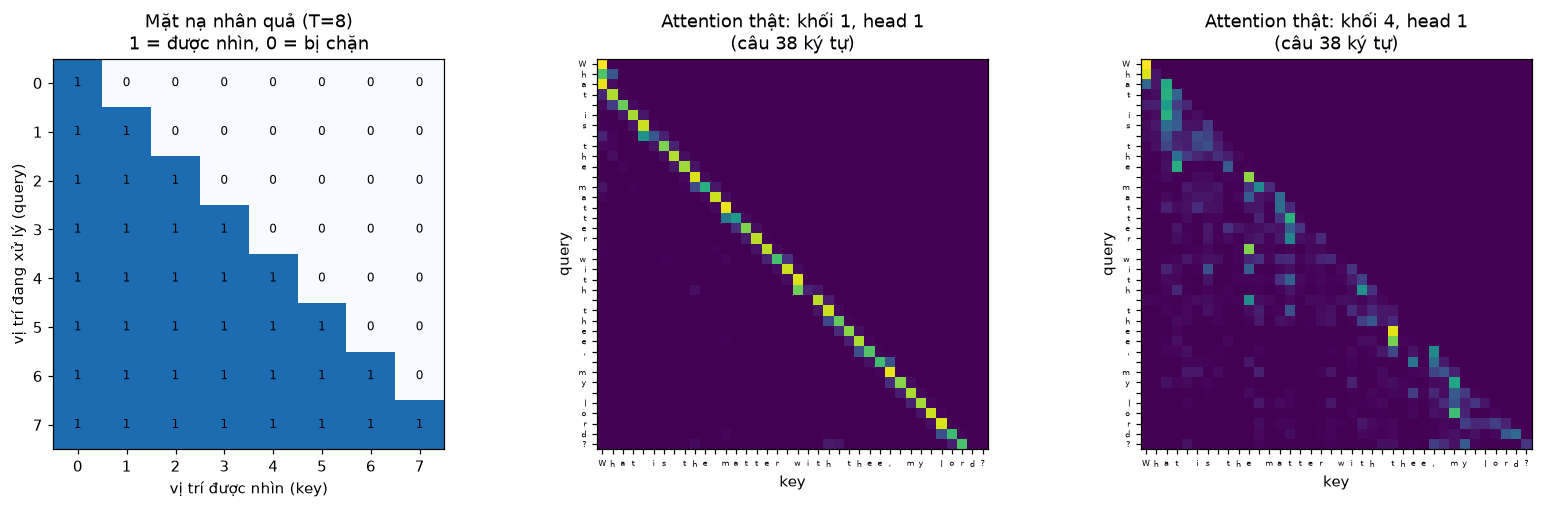

Trọng số attention lớn nhất ở nửa tam giác trên (tương lai), trên mọi khối và head: 0.0


In [ ]:
sentence = "What is the matter with thee, my lord?"
ids = torch.tensor([tok.encode(sentence)])
T = ids.shape[1]
with torch.no_grad():
    logits, _, atts = model(ids, return_att=True)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
toy = np.tril(np.ones((8, 8)))
axes[0].imshow(toy, cmap="Blues", vmin=0, vmax=1.3); axes[0].set_title("Mặt nạ nhân quả (T=8)\n1 = được nhìn, 0 = bị chặn")
axes[0].set_xlabel("vị trí được nhìn (key)"); axes[0].set_ylabel("vị trí đang xử lý (query)")
for (i, j), v in np.ndenumerate(toy):
    axes[0].text(j, i, int(v), ha="center", va="center", fontsize=8)
for ax, (layer, head) in zip(axes[1:], [(0, 0), (len(atts) - 1, 0)]):
    a = atts[layer][0, head].numpy()
    ax.imshow(a, cmap="viridis"); ax.set_title(f"Attention thật: khối {layer+1}, head {head+1}\n(câu {T} ký tự)")
    ax.set_xticks(range(T)); ax.set_xticklabels(list(sentence), fontsize=5); ax.set_yticks(range(T)); ax.set_yticklabels(list(sentence), fontsize=5)
    ax.set_xlabel("key"); ax.set_ylabel("query")
plt.tight_layout(); plt.savefig("figures/fig2_causal_mask_attention.png", bbox_inches="tight"); plt.show()
upper = max(float(a[0, h][torch.triu(torch.ones(T, T), 1).bool()].abs().max()) for a in atts for h in range(a.shape[1]))
print(f"Trọng số attention lớn nhất ở nửa tam giác trên (tương lai), trên mọi khối và head: {upper}")

In [ ]:
# Kiểm tra tính nhân quả: đổi toàn bộ token từ vị trí k trở đi, so sánh logits.
k = 20
x1 = ids.clone(); x2 = ids.clone()
g = torch.Generator().manual_seed(1)
x2[0, k:] = torch.randint(0, tok.vocab_size, (T - k,), generator=g)
with torch.no_grad():
    l1, _ = model(x1); l2, _ = model(x2)
d_before = (l1[0, :k] - l2[0, :k]).abs().max().item()
d_after = (l1[0, k:] - l2[0, k:]).abs().max().item()
print(f"Đổi các ký tự từ vị trí {k} trở đi:")
print(f"  chênh lệch logits lớn nhất ở các vị trí < {k} (phía trước): {d_before:.2e}")
print(f"  chênh lệch logits lớn nhất ở các vị trí >= {k} (bị đổi):   {d_after:.3f}")
assert d_before < 1e-5 and d_after > 1e-3

Đổi các ký tự từ vị trí 20 trở đi:
  chênh lệch logits lớn nhất ở các vị trí < 20 (phía trước): 0.00e+00
  chênh lệch logits lớn nhất ở các vị trí >= 20 (bị đổi):   14.587


In [ ]:
# Luồng dữ liệu thật, từng bước, với kích thước tensor.
with torch.no_grad():
    te = model.tok_emb(ids); pe = model.pos_emb(torch.arange(T))[None]
    x = te + pe
    rows = [("Văn bản", f"'{sentence}'", f"{T} ký tự"),
            ("Tokenizer -> token ID", str(ids[0, :8].tolist()) + " ...", tuple(ids.shape)),
            ("Embedding token", "tok_emb[ID]", tuple(te.shape)),
            ("+ Embedding vị trí", "tok_emb + pos_emb", tuple(x.shape))]
    for i, b in enumerate(model.blocks):
        x = b(x); rows.append((f"Khối Transformer {i+1}", "masked self-attention -> MLP (+ residual, LayerNorm)", tuple(x.shape)))
    lg = model.lm_head(model.ln_f(x)); rows.append(("LayerNorm + lớp tuyến tính", "-> logits cho mọi vị trí", tuple(lg.shape)))
    probs = F.softmax(lg[0, -1], dim=-1)
    rows.append(("Softmax ở vị trí cuối", "-> P(ký tự kế tiếp)", tuple(probs.shape)))
assert torch.allclose(lg, logits, atol=1e-5)  # khớp với forward() của mô hình
display(pd.DataFrame(rows, columns=["Bước", "Phép tính", "Kích thước"]))
top = torch.topk(probs, 5)
print(f"Sau '{sentence}', 5 ký tự kế tiếp có xác suất cao nhất:")
print(pd.DataFrame({"ký tự": [repr(tok.itos[int(i)]) for i in top.indices], "xác suất": [round(float(p), 3) for p in top.values]}).to_string(index=False))
print(f"Tổng xác suất trên toàn bộ {tok.vocab_size} ký tự = {float(probs.sum()):.4f}")

,Bước,Phép tính,Kích thước
0,Văn bản,"'What is the matter with thee, my lord?'",38 ký tự
1,Tokenizer -> token ID,"[35, 46, 39, 58, 1, 47, 57, 1] ...","(1, 38)"
2,Embedding token,tok_emb[ID],"(1, 38, 128)"
3,+ Embedding vị trí,tok_emb + pos_emb,"(1, 38, 128)"
4,Khối Transformer 1,"masked self-attention -> MLP (+ residual, LayerNorm)","(1, 38, 128)"
5,Khối Transformer 2,"masked self-attention -> MLP (+ residual, LayerNorm)","(1, 38, 128)"
6,Khối Transformer 3,"masked self-attention -> MLP (+ residual, LayerNorm)","(1, 38, 128)"
7,Khối Transformer 4,"masked self-attention -> MLP (+ residual, LayerNorm)","(1, 38, 128)"
8,LayerNorm + lớp tuyến tính,-> logits cho mọi vị trí,"(1, 38, 65)"
9,Softmax ở vị trí cuối,-> P(ký tự kế tiếp),"(65,)"


Sau 'What is the matter with thee, my lord?', 5 ký tự kế tiếp có xác suất cao nhất:
ký tự  xác suất
 '\n'     0.931
  ' '     0.065
  "'"     0.003
  '-'     0.001
  '.'     0.000
Tổng xác suất trên toàn bộ 65 ký tự = 1.0000


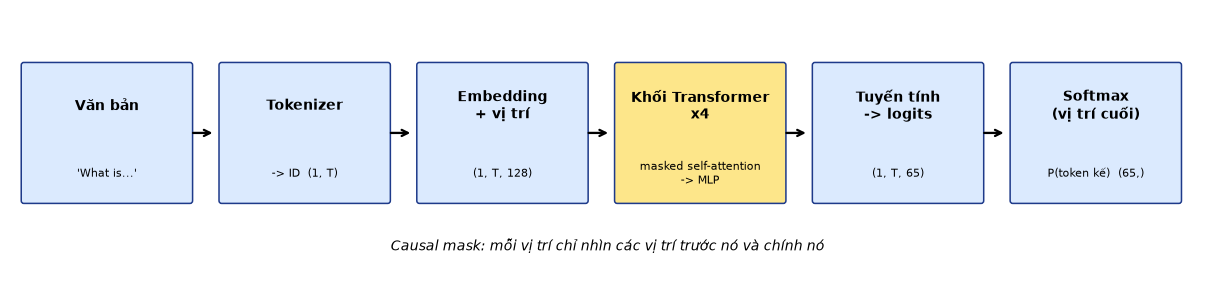

In [ ]:
# Sơ đồ luồng dữ liệu
fig, ax = plt.subplots(figsize=(14, 3.2)); ax.axis("off"); ax.set_xlim(0, 14); ax.set_ylim(0, 3)
steps = [("Văn bản", "'What is...'"), ("Tokenizer", f"-> ID  (1, T)"), ("Embedding\n+ vị trí", f"(1, T, {ckpt['cfg']['n_embd']})"),
         (f"Khối Transformer\nx{ckpt['cfg']['n_layer']}", "masked self-attention\n-> MLP"), ("Tuyến tính\n-> logits", f"(1, T, {tok.vocab_size})"),
         ("Softmax\n(vị trí cuối)", f"P(token kế)  ({tok.vocab_size},)")]
w = 1.95
for i, (a, b) in enumerate(steps):
    x0 = 0.15 + i * 2.32
    ax.add_patch(FancyBboxPatch((x0, 0.9), w, 1.5, boxstyle="round,pad=0.03", fc="#dbeafe" if i != 3 else "#fde68a", ec="#1e3a8a"))
    ax.text(x0 + w / 2, 1.95, a, ha="center", va="center", fontsize=9, weight="bold")
    ax.text(x0 + w / 2, 1.2, b, ha="center", va="center", fontsize=7.5)
    if i < len(steps) - 1:
        ax.annotate("", xy=(x0 + w + 0.3, 1.65), xytext=(x0 + w, 1.65), arrowprops=dict(arrowstyle="->", lw=1.5))
ax.text(7, 0.35, "Causal mask: mỗi vị trí chỉ nhìn các vị trí trước nó và chính nó", ha="center", fontsize=9, style="italic")
plt.savefig("figures/fig2_pipeline.png", bbox_inches="tight"); plt.show()

## Mục 3 – Tokenization: token, token ID và embedding

Hai tokenizer thật, đều là biến thể BPE:
- **GPT-2** (byte-level BPE, từ vựng 50.257 token, huấn luyện chủ yếu trên văn bản tiếng Anh từ web).
- **Llama 2** (SentencePiece BPE, từ vựng 32.000 token).

Chú ý: mảnh dạng `<e1 bb 99>` là các **byte lẻ** của một ký tự UTF-8 có dấu – tokenizer byte-level được phép cắt giữa một ký tự.

In [ ]:
E = tok_utils.load_gpt2(); SP = tok_utils.load_llama2()
EN = "Large language models learn to predict the next token."
VI = "Mô hình ngôn ngữ lớn học cách dự đoán token tiếp theo."
TOKENIZERS = {"GPT-2 BPE": lambda s: tok_utils.gpt2_tokenize(E, s), "Llama 2 SP": lambda s: tok_utils.llama2_tokenize(SP, s)}

rows = []
for name, fn in TOKENIZERS.items():
    for lang, s in (("Anh", EN), ("Việt", VI)):
        ids_, pieces = fn(s)
        rows.append(dict(tokenizer=name, ngôn_ngữ=lang, ký_tự=len(s), token=len(ids_), ký_tự_trên_token=round(len(s) / len(ids_), 2)))
        print(f"[{name} | {lang}] {s}")
        print("  mảnh :", pieces)
        print("  ID   :", ids_)
display(pd.DataFrame(rows))

[GPT-2 BPE | Anh] Large language models learn to predict the next token.
  mảnh : ['Large', ' language', ' models', ' learn', ' to', ' predict', ' the', ' next', ' token', '.']
  ID   : [21968, 3303, 4981, 2193, 284, 4331, 262, 1306, 11241, 13]
[GPT-2 BPE | Việt] Mô hình ngôn ngữ lớn học cách dự đoán token tiếp theo.
  mảnh : ['M', 'ô', ' h', '<c3>', '<ac>', 'n', 'h', ' ng', 'ô', 'n', ' ng', '<e1>', '<bb>', '<af>', ' l', '<e1>', '<bb>', '<9b>', 'n', ' h', '<e1>', '<bb>', '<8d>', 'c', ' c', 'á', 'ch', ' d', '<e1>', '<bb>', '<b1>', '<20 c4>', '<91>', 'o', 'án', ' token', ' ti', '<e1>', '<ba>', '<bf>', 'p', ' the', 'o', '.']
  ID   : [44, 27083, 289, 127, 105, 77, 71, 23370, 27083, 77, 23370, 157, 119, 107, 300, 157, 119, 249, 77, 289, 157, 119, 235, 66, 269, 6557, 354, 288, 157, 119, 109, 34754, 239, 78, 21162, 11241, 46668, 157, 118, 123, 79, 262, 78, 13]
[Llama 2 SP | Anh] Large language models learn to predict the next token.
  mảnh : ['▁Lar', 'ge', '▁language', '▁models', '▁learn', '

,tokenizer,ngôn_ngữ,ký_tự,token,ký_tự_trên_token
0,GPT-2 BPE,Anh,54,10,5.40
1,GPT-2 BPE,Việt,54,44,1.23
2,Llama 2 SP,Anh,54,11,4.91
3,Llama 2 SP,Việt,54,32,1.69


,câu Anh,GPT-2 BPE: Anh,GPT-2 BPE: Việt,GPT-2 BPE: Việt/Anh,Llama 2 SP: Anh,Llama 2 SP: Việt,Llama 2 SP: Việt/Anh
0,The capital of Vietnam is Hanoi.,9,28,3.11,9,19,2.11
1,I would like to order two cups of coff…,10,21,2.10,11,17,1.55
2,Machine learning models need a lot of …,9,44,4.89,9,29,3.22
3,The delivery was late but the product …,10,39,3.90,10,32,3.20
4,Please check the weather forecast for …,8,35,4.38,10,25,2.50
5,She teaches mathematics at a universit…,13,61,4.69,14,43,3.07
6,Large language models learn to predict…,10,44,4.40,11,32,2.91


Tỉ lệ số token Việt/Anh trung bình: {'GPT-2 BPE': 3.92, 'Llama 2 SP': 2.65}


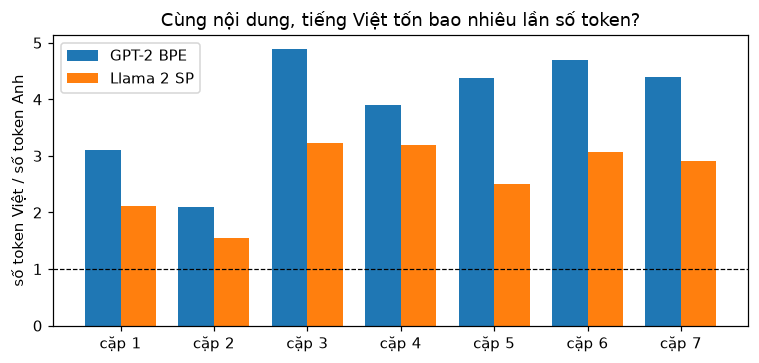

In [ ]:
# Tokenize nhiều cặp câu song song (cùng nội dung, hai ngôn ngữ) để so sánh số token.
pairs = [
    ("The capital of Vietnam is Hanoi.", "Thủ đô của Việt Nam là Hà Nội."),
    ("I would like to order two cups of coffee.", "Tôi muốn gọi hai ly cà phê."),
    ("Machine learning models need a lot of data.", "Các mô hình học máy cần rất nhiều dữ liệu."),
    ("The delivery was late but the product works well.", "Giao hàng chậm nhưng sản phẩm dùng rất ổn."),
    ("Please check the weather forecast for tomorrow.", "Vui lòng kiểm tra dự báo thời tiết ngày mai."),
    ("She teaches mathematics at a university in Ho Chi Minh City.", "Cô ấy dạy toán tại một trường đại học ở Thành phố Hồ Chí Minh."),
    (EN, VI),
]
rows = []
for en, vi in pairs:
    r = {"câu Anh": en[:38] + ("…" if len(en) > 38 else "")}
    for name, fn in TOKENIZERS.items():
        ne, nv = len(fn(en)[0]), len(fn(vi)[0])
        r[f"{name}: Anh"], r[f"{name}: Việt"], r[f"{name}: Việt/Anh"] = ne, nv, round(nv / ne, 2)
    rows.append(r)
pair_df = pd.DataFrame(rows)
display(pair_df)
ratio = {n: float(np.mean(pair_df[f"{n}: Việt/Anh"])) for n in TOKENIZERS}
print("Tỉ lệ số token Việt/Anh trung bình:", {k: round(v, 2) for k, v in ratio.items()})
fig, ax = plt.subplots(figsize=(7, 3.4))
idx = np.arange(len(pair_df)); wd = 0.38
for j, n in enumerate(TOKENIZERS):
    ax.bar(idx + (j - 0.5) * wd, pair_df[f"{n}: Việt/Anh"], wd, label=n)
ax.axhline(1, color="k", lw=0.8, ls="--"); ax.set_xticks(idx); ax.set_xticklabels([f"cặp {i+1}" for i in idx])
ax.set_ylabel("số token Việt / số token Anh"); ax.set_title("Cùng nội dung, tiếng Việt tốn bao nhiêu lần số token?"); ax.legend()
plt.tight_layout(); plt.savefig("figures/fig3_token_ratio.png", bbox_inches="tight"); plt.show()
pair_df.to_csv("results/tokenization_pairs.csv", index=False)

In [ ]:
# Từ token ID đến embedding, minh họa bằng bảng embedding của MiniGPT (mức ký tự).
Emb = model.tok_emb.weight.detach()
print("Ma trận embedding:", tuple(Emb.shape), "= (số token trong từ vựng, số chiều)")
cid = tok.stoi["a"]
print(f"Ký tự 'a' có ID {cid}; embedding của nó = hàng {cid} của ma trận: {np.round(Emb[cid, :6].numpy(), 3)} ...")
assert torch.equal(model.tok_emb(torch.tensor([cid]))[0], Emb[cid])

def mean_cos(E_, A, B):
    En = F.normalize(E_, dim=1); vals = []
    for a in A:
        for b in B:
            if a != b: vals.append(float(En[tok.stoi[a]] @ En[tok.stoi[b]]))
    return np.mean(vals)
vowels, cons = list("aeiou"), list("bcdfgklmnprstw")
torch.manual_seed(123); rand_model = MiniGPT(**ckpt["cfg"]); Er = rand_model.tok_emb.weight.detach()
tbl = pd.DataFrame({"nguyên âm–nguyên âm": [mean_cos(Er, vowels, vowels), mean_cos(Emb, vowels, vowels)],
                    "phụ âm–phụ âm": [mean_cos(Er, cons, cons), mean_cos(Emb, cons, cons)],
                    "nguyên âm–phụ âm": [mean_cos(Er, vowels, cons), mean_cos(Emb, vowels, cons)]},
                   index=["chưa huấn luyện (ngẫu nhiên)", "đã huấn luyện"]).round(3)
display(tbl)
print("(Độ tương đồng cosine trung bình giữa các embedding ký tự. Chỉ là quan sát trên mô hình nhỏ này.)")

Ma trận embedding: (65, 128) = (số token trong từ vựng, số chiều)
Ký tự 'a' có ID 39; embedding của nó = hàng 39 của ma trận: [ 0.094  0.043  0.042  0.169  0.061 -0.235] ...


,nguyên âm–nguyên âm,phụ âm–phụ âm,nguyên âm–phụ âm
chưa huấn luyện (ngẫu nhiên),-0.003,-0.002,-0.008
đã huấn luyện,0.182,0.082,-0.048


(Độ tương đồng cosine trung bình giữa các embedding ký tự. Chỉ là quan sát trên mô hình nhỏ này.)


## Mục 4 – Nguyên lý học: next-token prediction và cross-entropy

In [ ]:
def make_pairs(pieces):
    return pd.DataFrame({"ngữ cảnh (đầu vào)": ["".join(pieces[:i]).replace("▁", " ") for i in range(1, len(pieces))],
                         "token mục tiêu": [repr(p.replace("▁", " ")) for p in pieces[1:]]})
s_en = "The capital of Vietnam is Hanoi."
s_vi = "Hà Nội là thủ đô của Việt Nam."
_, p_en = tok_utils.gpt2_tokenize(E, s_en)
_, p_vi = tok_utils.llama2_tokenize(SP, s_vi)
print(f"Câu Anh, tokenizer GPT-2 -> {len(p_en)} token -> {len(p_en)-1} cặp huấn luyện"); display(make_pairs(p_en))
print(f"Câu Việt, tokenizer Llama 2 -> {len(p_vi)} token -> {len(p_vi)-1} cặp huấn luyện"); display(make_pairs(p_vi))

Câu Anh, tokenizer GPT-2 -> 9 token -> 8 cặp huấn luyện


,ngữ cảnh (đầu vào),token mục tiêu
0,The,' capital'
1,The capital,' of'
2,The capital of,' Vietnam'
3,The capital of Vietnam,' is'
4,The capital of Vietnam is,' H'
5,The capital of Vietnam is H,'ano'
6,The capital of Vietnam is Hano,'i'
7,The capital of Vietnam is Hanoi,'.'


Câu Việt, tokenizer Llama 2 -> 19 token -> 18 cặp huấn luyện


,ngữ cảnh (đầu vào),token mục tiêu
0,H,'à'
1,Hà,' N'
2,Hà N,'ộ'
3,Hà Nộ,'i'
4,Hà Nội,' là'
5,Hà Nội là,' th'
6,Hà Nội là th,'ủ'
7,Hà Nội là thủ,' '
8,Hà Nội là thủ,'đ'
9,Hà Nội là thủ đ,'ô'


In [ ]:
# Cross-entropy thật của MiniGPT trên từng vị trí.
def per_position_loss(text):
    x = torch.tensor([tok.encode(text)])
    with torch.no_grad():
        lg, _ = model(x[:, :-1])
    logp = F.log_softmax(lg[0], dim=-1)
    tgt = x[0, 1:]
    nll = -logp.gather(1, tgt[:, None])[:, 0]
    ref = F.cross_entropy(lg[0], tgt)
    assert abs(float(nll.mean()) - float(ref)) < 1e-5     # khớp F.cross_entropy
    df = pd.DataFrame({"ngữ cảnh (cuối)": ["…" + text[max(0, i + 1 - 12):i + 1] for i in range(len(tgt))],
                       "ký tự đích": [repr(text[i + 1]) for i in range(len(tgt))],
                       "P(đích)": [round(float(math.exp(-v)), 4) for v in nll],
                       "loss = -ln P": [round(float(v), 3) for v in nll]})
    return df, float(nll.mean())

val_text = corpus[int(0.9 * len(corpus)):]
line = next(l for l in val_text.split("\n") if len(l) > 40)     # một dòng thuộc tập kiểm định
modern = "The weather is nice today, let us go out."
results4 = {}
for name, text in (("dòng trong tập val (văn Shakespeare, mô hình chưa thấy)", line), ("câu tiếng Anh hiện đại (khác phân phối dữ liệu)", modern)):
    df, m = per_position_loss(text); results4[name] = (df, m)
    print(f"\n### {name}\n{text!r}\nloss trung bình = {m:.3f} | perplexity = exp(loss) = {math.exp(m):.2f}")
    display(df.head(12))
print(f"\nMốc so sánh: đoán đều ngẫu nhiên trên {tok.vocab_size} ký tự -> loss = ln({tok.vocab_size}) = {math.log(tok.vocab_size):.3f}, perplexity = {tok.vocab_size}")
print("Ghi chú: perplexity ở đây tính theo KÝ TỰ nên không so sánh được với perplexity theo token của mô hình khác.")
print("Hai câu đơn lẻ chỉ mang tính minh họa (không phải đo lường tổng quát); loss trên toàn tập val ở bảng đường học bên dưới.")


### dòng trong tập val (văn Shakespeare, mô hình chưa thấy)
'And you, good sir! Pray, have you not a daughter'
loss trung bình = 1.162 | perplexity = exp(loss) = 3.20


,ngữ cảnh (cuối),ký tự đích,P(đích),loss = -ln P
0,…A,'n',0.1991,1.614
1,…An,'d',0.8467,0.166
2,…And,' ',0.9105,0.094
3,…And,'y',0.0443,3.116
4,…And y,'o',0.8481,0.165
5,…And yo,'u',0.9964,0.004
6,…And you,"','",0.0589,2.831
7,"…And you,",' ',0.9215,0.082
8,"…And you,",'g',0.0421,3.169
9,"…And you, g",'o',0.6209,0.477



### câu tiếng Anh hiện đại (khác phân phối dữ liệu)
'The weather is nice today, let us go out.'
loss trung bình = 1.993 | perplexity = exp(loss) = 7.34


,ngữ cảnh (cuối),ký tự đích,P(đích),loss = -ln P
0,…T,'h',0.3684,0.998
1,…Th,'e',0.3773,0.975
2,…The,' ',0.4983,0.697
3,…The,'w',0.0719,2.633
4,…The w,'e',0.0914,2.392
5,…The we,'a',0.2200,1.514
6,…The wea,'t',0.0315,3.456
7,…The weat,'h',0.2041,1.589
8,…The weath,'e',0.3139,1.159
9,…The weathe,'r',0.9326,0.070



Mốc so sánh: đoán đều ngẫu nhiên trên 65 ký tự -> loss = ln(65) = 4.174, perplexity = 65
Ghi chú: perplexity ở đây tính theo KÝ TỰ nên không so sánh được với perplexity theo token của mô hình khác.
Hai câu đơn lẻ chỉ mang tính minh họa (không phải đo lường tổng quát); loss trên toàn tập val ở bảng đường học bên dưới.


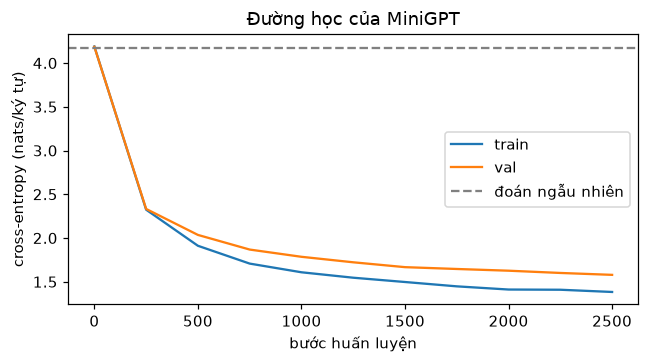

,step,train_loss,val_loss,seconds
0,0,4.190,4.186,5.7
1,250,2.324,2.332,109.1
2,500,1.911,2.035,213.5
3,750,1.708,1.868,324.2
4,1000,1.608,1.785,425.5
5,1250,1.546,1.722,526.6
6,1500,1.497,1.667,629.9
7,1750,1.448,1.646,731.1
8,2000,1.411,1.626,832.1
9,2250,1.409,1.601,934.1


In [ ]:
h = pd.DataFrame(hist["history"])
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.plot(h.step, h.train_loss, label="train"); ax.plot(h.step, h.val_loss, label="val"); ax.axhline(math.log(tok.vocab_size), ls="--", c="gray", label="đoán ngẫu nhiên")
ax.set_xlabel("bước huấn luyện"); ax.set_ylabel("cross-entropy (nats/ký tự)"); ax.set_title("Đường học của MiniGPT"); ax.legend()
plt.tight_layout(); plt.savefig("figures/fig4_loss_curve.png", bbox_inches="tight"); plt.show()
display(h.round(3))

## Mục 5 – Các giai đoạn huấn luyện và phương pháp căn chỉnh sở thích (RLHF / DPO)

Mô hình MiniGPT minh họa cho giai đoạn Pretraining (tiền huấn luyện tự giám sát). Các giai đoạn Supervised Fine-Tuning (SFT) và Alignment (RLHF/DPO) yêu cầu dữ liệu hội thoại và cặp ưa thích; phần dưới đây trình bày sơ đồ kiến trúc tổng quan và tính toán số học minh họa hàm mục tiêu DPO.

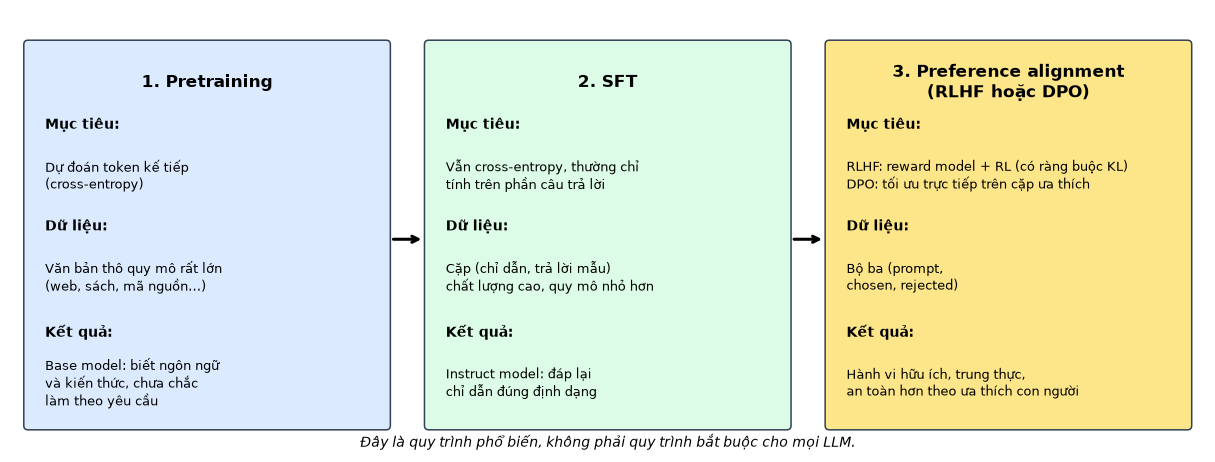

In [ ]:
fig, ax = plt.subplots(figsize=(14, 5.2)); ax.axis("off"); ax.set_xlim(0, 14); ax.set_ylim(0, 5.2)
stages = [("1. Pretraining", "#dbeafe", "Dự đoán token kế tiếp\n(cross-entropy)", "Văn bản thô quy mô rất lớn\n(web, sách, mã nguồn…)", "Base model: biết ngôn ngữ\nvà kiến thức, chưa chắc\nlàm theo yêu cầu"),
          ("2. SFT", "#dcfce7", "Vẫn cross-entropy, thường chỉ\ntính trên phần câu trả lời", "Cặp (chỉ dẫn, trả lời mẫu)\nchất lượng cao, quy mô nhỏ hơn", "Instruct model: đáp lại\nchỉ dẫn đúng định dạng"),
          ("3. Preference alignment\n(RLHF hoặc DPO)", "#fde68a", "RLHF: reward model + RL (có ràng buộc KL)\nDPO: tối ưu trực tiếp trên cặp ưa thích", "Bộ ba (prompt,\nchosen, rejected)", "Hành vi hữu ích, trung thực,\nan toàn hơn theo ưa thích con người")]
for i, (title, col, goal, data, out) in enumerate(stages):
    x0 = 0.2 + i * 4.7
    ax.add_patch(FancyBboxPatch((x0, 0.3), 4.2, 4.5, boxstyle="round,pad=0.05", fc=col, ec="#334155"))
    ax.text(x0 + 2.1, 4.35, title, ha="center", va="center", weight="bold", fontsize=11)
    for y, lab, txt in ((3.4, "Mục tiêu", goal), (2.2, "Dữ liệu", data), (0.95, "Kết quả", out)):
        ax.text(x0 + 0.2, y + 0.45, lab + ":", weight="bold", fontsize=9, va="center"); ax.text(x0 + 0.2, y - 0.15, txt, fontsize=8.5, va="center")
    if i < 2:
        ax.annotate("", xy=(x0 + 4.65, 2.5), xytext=(x0 + 4.25, 2.5), arrowprops=dict(arrowstyle="->", lw=2))
ax.text(7, 0.05, "Đây là quy trình phổ biến, không phải quy trình bắt buộc cho mọi LLM.", ha="center", fontsize=9, style="italic")
plt.savefig("figures/fig5_training_stages.png", bbox_inches="tight"); plt.show()

In [ ]:
# Phép tính số minh họa (giá trị giả định, không phải kết quả huấn luyện thật).
sig = lambda v: 1 / (1 + math.exp(-v))
r_w, r_l = 1.8, 0.4
print(f"Reward model (Bradley-Terry): r(chosen)={r_w}, r(rejected)={r_l} -> loss = -ln sigmoid(r_w - r_l) = {-math.log(sig(r_w - r_l)):.3f}")
beta = 0.1
def dpo_loss(lp_pol, lp_ref):
    margin = beta * ((lp_pol["w"] - lp_ref["w"]) - (lp_pol["l"] - lp_ref["l"]))
    return margin, -math.log(sig(margin))
ref = {"w": -13.0, "l": -14.0}                       # log P(câu | prompt) của mô hình tham chiếu (SFT)
for name, pol in (("trước khi tối ưu (policy = tham chiếu)", dict(ref)), ("sau khi tối ưu (chosen tăng, rejected giảm)", {"w": -11.0, "l": -16.0})):
    m, l = dpo_loss(pol, ref); print(f"DPO – {name}: margin = {m:+.2f}, loss = {l:.3f}")
print("-> DPO kéo xác suất câu 'chosen' lên và câu 'rejected' xuống (so với mô hình tham chiếu), không cần reward model riêng.")

Reward model (Bradley-Terry): r(chosen)=1.8, r(rejected)=0.4 -> loss = -ln sigmoid(r_w - r_l) = 0.220
DPO – trước khi tối ưu (policy = tham chiếu): margin = +0.00, loss = 0.693
DPO – sau khi tối ưu (chosen tăng, rejected giảm): margin = +0.40, loss = 0.513
-> DPO kéo xác suất câu 'chosen' lên và câu 'rejected' xuống (so với mô hình tham chiếu), không cần reward model riêng.


## Mục 6 – Quá trình sinh văn bản: autoregressive, greedy, temperature, top-p

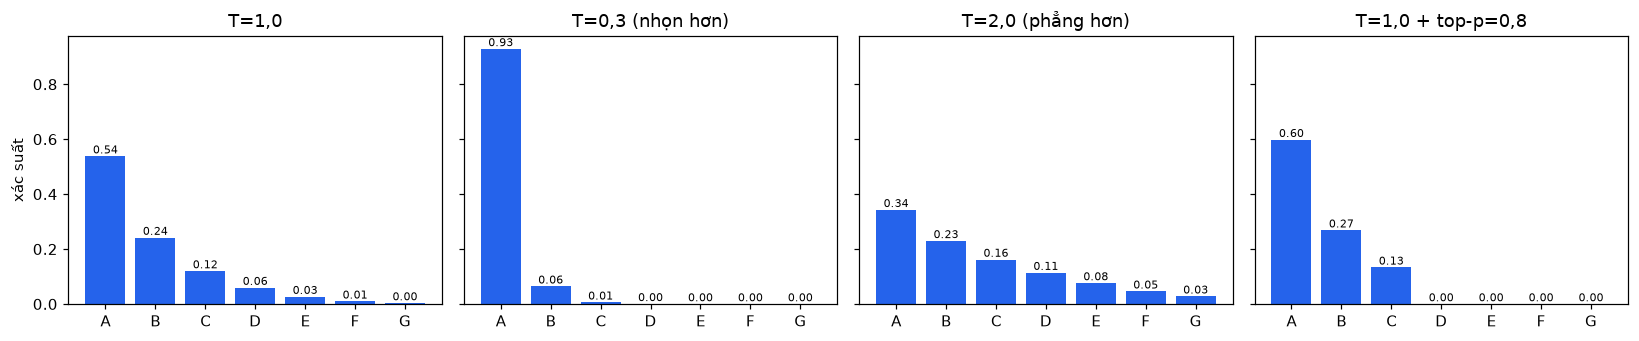

Top-p=0,8: giữ tập token nhỏ nhất có tổng xác suất tích lũy >= 0,8 rồi chuẩn hóa lại; các token còn lại bị đặt bằng 0.


In [ ]:
# (a) Temperature và top-p tác động lên một phân phối cụ thể (logits giả định).
labels = list("ABCDEFG"); logits_toy = torch.tensor([3.0, 2.2, 1.5, 0.8, 0.0, -1.0, -2.0])
fig, axes = plt.subplots(1, 4, figsize=(15, 3.2), sharey=True)
for ax, (T_, p_, title) in zip(axes, [(1.0, 1.0, "T=1,0"), (0.3, 1.0, "T=0,3 (nhọn hơn)"), (2.0, 1.0, "T=2,0 (phẳng hơn)"), (1.0, 0.8, "T=1,0 + top-p=0,8")]):
    p = adjust_probs(logits_toy, T_, p_).numpy()
    ax.bar(labels, p, color=["#2563eb" if v > 0 else "#cbd5e1" for v in p]); ax.set_title(title)
    for i, v in enumerate(p):
        ax.text(i, v + 0.01, f"{v:.2f}", ha="center", fontsize=7)
axes[0].set_ylabel("xác suất")
plt.tight_layout(); plt.savefig("figures/fig6_temperature_topp.png", bbox_inches="tight"); plt.show()
print("Top-p=0,8: giữ tập token nhỏ nhất có tổng xác suất tích lũy >= 0,8 rồi chuẩn hóa lại; các token còn lại bị đặt bằng 0.")

In [ ]:
# (b) Cùng MỘT prompt, các cấu hình sinh khác nhau, trên MiniGPT thật.
PROMPT = "ROMEO:\n"
CONFIGS = {"greedy": dict(greedy=True), "T=0.3": dict(T=0.3), "T=0.8": dict(T=0.8), "T=0.8, top-p=0.95": dict(T=0.8, p=0.95),
           "T=1.0": dict(T=1.0), "T=1.5": dict(T=1.5)}
N_NEW, N_SAMPLES = 160, 30

def sample_text(cfg, seed):
    g = torch.Generator().manual_seed(seed)
    x = torch.tensor([tok.encode(PROMPT)])
    out = generate(model, x, N_NEW, temperature=cfg.get("T", 1.0), top_p=cfg.get("p", 1.0), greedy=cfg.get("greedy", False), generator=g)
    return tok.decode(out[0])[len(PROMPT):]

samples = {}
for name, cfg in CONFIGS.items():
    n = 3 if cfg.get("greedy") else N_SAMPLES
    samples[name] = [sample_text(cfg, seed) for seed in range(n)]
print("Greedy chạy lại có giống nhau không (cùng mô hình, đầu vào, cấu hình)?", samples["greedy"][0] == sample_text(CONFIGS["greedy"], 99))
for name in CONFIGS:
    print(f"\n===== {name} =====")
    for s in samples[name][:2 if name != "greedy" else 1]:
        print(repr(s))

Greedy chạy lại có giống nhau không (cùng mô hình, đầu vào, cấu hình)? True

===== greedy =====
'I will be so make the stand of the sent of the sent\nThat the sent of the sent of the senter of the sent\nThat the seat of the sent of the seat of the seat,\nAnd t'

===== T=0.3 =====
'There have here not so shall be so did the strange\nThat you have here been the seems of my serves,\nAnd that I will be here in the crown of the sent\nThat the day'
'What shall say the grace of my lord.\n\nCAPULET:\nThe virtue of the state of his face of the state,\nAnd see the father of the prison of his seats,\nThat was the put'

===== T=0.8 =====
'Thou must there not made a means by the gelse,\nAnd prayer his true receitor of such life.\n\nPRINCE EDWARD:\nTo his persuices is did true nemy father well.\n\nRICHAR'
'What speak so me us leave my eye,\nAnd shame with a virtue countiness in this poor\nall tale thee show grat of the king:\nBy then bears as for there the measure, t'

===== T=0.8, top-p=0.95 =====


,cấu_hình,số_mẫu,tỉ_lệ_từ_không_có_trong_dữ_liệu,distinct2_từ,lặp_bộ_ba_từ,mẫu_khác_nhau
0,greedy,3,0.051,0.474,0.405,1
1,T=0.3,30,0.017,0.885,0.018,30
2,T=0.8,30,0.097,0.995,0.000,30
3,"T=0.8, top-p=0.95",30,0.059,0.994,0.000,30
4,T=1.0,30,0.160,0.998,0.001,30
5,T=1.5,30,0.382,1.000,0.000,30


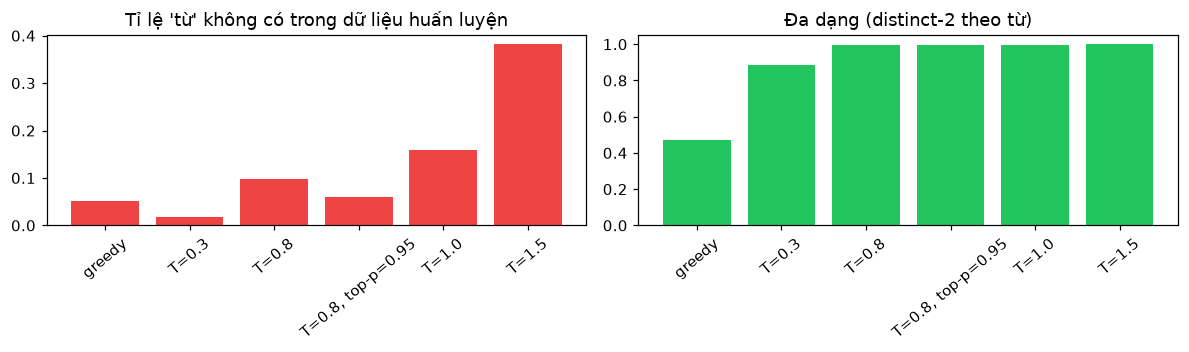

In [ ]:
# (c) Đo định lượng, mỗi cấu hình 30 mẫu x 160 ký tự (greedy chỉ 3 mẫu vì xác định).
word_set = set(re.findall(r"[a-z']+", corpus.lower()))
words = lambda s: re.findall(r"[a-z']+", s.lower())
def metrics(text):
    w = words(text); tri = list(zip(w, w[1:], w[2:])); bi = list(zip(w, w[1:]))
    return dict(non_word=np.mean([x not in word_set for x in w]) if w else np.nan,
                distinct2=len(set(bi)) / len(bi) if bi else np.nan,
                repeat3=1 - len(set(tri)) / len(tri) if tri else np.nan)
rows = []
for name, ss in samples.items():
    m = pd.DataFrame([metrics(s) for s in ss])
    rows.append(dict(cấu_hình=name, số_mẫu=len(ss), tỉ_lệ_từ_không_có_trong_dữ_liệu=round(m.non_word.mean(), 3),
                     distinct2_từ=round(m.distinct2.mean(), 3), lặp_bộ_ba_từ=round(m.repeat3.mean(), 3),
                     mẫu_khác_nhau=len(set(ss))))
dec_df = pd.DataFrame(rows); display(dec_df); dec_df.to_csv("results/decoding_metrics.csv", index=False)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.3))
ax[0].bar(dec_df["cấu_hình"], dec_df["tỉ_lệ_từ_không_có_trong_dữ_liệu"], color="#ef4444"); ax[0].set_title("Tỉ lệ 'từ' không có trong dữ liệu huấn luyện"); ax[0].tick_params(axis="x", rotation=40)
ax[1].bar(dec_df["cấu_hình"], dec_df["distinct2_từ"], color="#22c55e"); ax[1].set_title("Đa dạng (distinct-2 theo từ)"); ax[1].tick_params(axis="x", rotation=40)
plt.tight_layout(); plt.savefig("figures/fig6_decoding_metrics.png", bbox_inches="tight"); plt.show()

## Mục 7 – Khả năng của LLM: In-context Learning (Zero-shot vs Few-shot)

Thực nghiệm có kiểm soát so sánh khả năng suy luận zero-shot và few-shot trên cùng một mô hình LLM (Qwen 2.5 7B, temperature = 0):

- **Tác vụ:** Phân loại cảm xúc 20 câu đánh giá tiếng Việt (`data/test_sentiment_vi.csv`), nhãn chuẩn xác định theo `data/labeling_rules.md`.
- **Biến can thiệp:** Bổ sung 6 ví dụ mẫu trong prompt (`data/fewshot_examples.csv`, hoàn toàn độc lập với tập kiểm tra).
- **Yếu tố kiểm soát:** Cố định mô hình, siêu tham số, tập dữ liệu kiểm tra và cơ chế đánh giá.
- **Dữ liệu kết quả:** Nạp trực tiếp từ `results/llm_summary.csv` và `results/llm_errors.csv`.

In [ ]:
test, shots = rle.load_data()
print("Phân bố nhãn:", test.gold.value_counts().to_dict(), "| độ khó:", test.difficulty.value_counts().to_dict())
print("Số câu few-shot trùng bộ test:", len(set(test.sentence) & set(shots.sentence)))
k = 4  # câu số 5: 'Giao hàng chậm nhưng sản phẩm dùng rất ổn.'
print("\n--- PROMPT ZERO-SHOT ---"); print(rle.build_prompt(test.sentence[k], "zero_shot", shots))
print("\n--- PROMPT FEW-SHOT ---"); print(rle.build_prompt(test.sentence[k], "few_shot", shots))

Phân bố nhãn: {'tích cực': 8, 'tiêu cực': 6, 'trung tính': 6} | độ khó: {'dễ': 13, 'khó': 7}
Số câu few-shot trùng bộ test: 0

--- PROMPT ZERO-SHOT ---
Phân loại cảm xúc của câu sau thành đúng một trong ba nhãn: tích cực, tiêu cực, trung tính.
Chỉ trả lời bằng đúng một nhãn, không giải thích.

Câu: "Giao hàng chậm nhưng sản phẩm dùng rất ổn."
Nhãn:

--- PROMPT FEW-SHOT ---
Phân loại cảm xúc của câu sau thành đúng một trong ba nhãn: tích cực, tiêu cực, trung tính.
Chỉ trả lời bằng đúng một nhãn, không giải thích.

Câu: "Quán ăn này sạch sẽ, món nào cũng ngon, phục vụ chu đáo."
Nhãn: tích cực

Câu: "Đặt hàng hai tuần mà vẫn chưa nhận được, liên hệ cũng không ai trả lời."
Nhãn: tiêu cực

Câu: "Chiếc áo có ba cỡ là S, M và L."
Nhãn: trung tính

Câu: "Chất vải mỏng quá, giặt một lần đã nhăn nhúm."
Nhãn: tiêu cực

Câu: "Cuốn sách gồm 12 chương và dày khoảng 300 trang."
Nhãn: trung tính

Câu: "Màn hình sáng rõ, loa to, dùng thích hơn tôi nghĩ."
Nhãn: tích cực

Câu: "Giao hàng chậm nhưng sản p

In [ ]:
summ_path = Path("results/llm_summary.csv")
if summ_path.exists():
    meta = json.load(open("results/llm_meta.json"))
    print("Mô hình:", meta["model"], "| ngày:", meta["date"], "| backend:", meta["backend"])
    display(pd.read_csv(summ_path)); display(pd.read_csv("results/llm_errors.csv"))
else:
    print("CHƯA CÓ KẾT QUẢ LLM THẬT (results/llm_summary.csv chưa tồn tại). Chạy run_llm_experiment.py rồi chạy lại notebook.")

Mô hình: qwen2.5:7b | ngày: 2026-11-16 | backend: openai_compat


,mode,n,accuracy,n_correct,acc_easy,acc_hard,format_ok,format_bad
0,few_shot,20,0.85,17,1.0,0.571,20,0
1,zero_shot,20,0.80,16,1.0,0.429,20,0


,mode,id,sentence,gold,pred,difficulty,note,output
0,zero_shot,5,Giao hàng chậm nhưng sản phẩm dùng rất ổn.,tích cực,trung tính,khó,hỗn hợp: theo ý sau từ 'nhưng',trung tính
1,zero_shot,11,"Pin tuyệt vời thật, sạc đầy dùng được đúng hai tiếng.",tiêu cực,trung tính,khó,mỉa mai,trung tính
2,zero_shot,19,Không thể nói là không hài lòng với dịch vụ này.,tích cực,trung tính,khó,phủ định kép,Trung tính
3,zero_shot,20,Hỏng hóc linh tinh nhưng bên bảo hành xử lý rất nhanh nên tôi vẫn yên tâm.,tích cực,trung tính,khó,hỗn hợp: theo ý sau từ 'nhưng',trung tính
4,few_shot,5,Giao hàng chậm nhưng sản phẩm dùng rất ổn.,tích cực,trung tính,khó,hỗn hợp: theo ý sau từ 'nhưng',trung tính
5,few_shot,19,Không thể nói là không hài lòng với dịch vụ này.,tích cực,trung tính,khó,phủ định kép,trung tính
6,few_shot,20,Hỏng hóc linh tinh nhưng bên bảo hành xử lý rất nhanh nên tôi vẫn yên tâm.,tích cực,trung tính,khó,hỗn hợp: theo ý sau từ 'nhưng',trung tính


## Mục 8 – Prompting, fine-tuning, RAG

Bảng so sánh, rồi một demo **phần truy xuất** của RAG chạy thật (TF-IDF theo n-gram ký tự) trên một kho tài liệu *giả lập* của một môn học. Bước sinh câu trả lời cần LLM nên chỉ dựng prompt, không chạy.

In [ ]:
display(pd.DataFrame({
    "Tiêu chí": ["Thay đổi trọng số", "Dữ liệu cần có", "Chi phí ban đầu", "Cập nhật tri thức", "Truy vết nguồn", "Phù hợp khi", "Hạn chế"],
    "Prompting": ["Không", "Vài ví dụ hoặc chỉ dẫn", "Rất thấp", "Sửa prompt", "Khó", "Thử nhanh, tác vụ chung", "Giới hạn ngữ cảnh; kém ổn định"],
    "Fine-tuning": ["Có", "Tập (đầu vào, đầu ra) chất lượng, quy mô phù hợp tác vụ", "Cao", "Huấn luyện lại", "Khó", "Cần phong cách/định dạng/hành vi ổn định", "Tốn kém; có thể giảm năng lực khác"],
    "RAG": ["Không", "Kho tài liệu chia đoạn + chỉ mục", "Trung bình", "Cập nhật kho tài liệu", "Dễ (trích đoạn nguồn)", "Hỏi đáp trên tài liệu riêng, tri thức hay đổi", "Chất lượng phụ thuộc truy xuất; vẫn có thể sinh sai"]}).set_index("Tiêu chí").T)

Tiêu chí,Thay đổi trọng số,Dữ liệu cần có,Chi phí ban đầu,Cập nhật tri thức,Truy vết nguồn,Phù hợp khi,Hạn chế
Prompting,Không,Vài ví dụ hoặc chỉ dẫn,Rất thấp,Sửa prompt,Khó,"Thử nhanh, tác vụ chung",Giới hạn ngữ cảnh; kém ổn định
Fine-tuning,Có,"Tập (đầu vào, đầu ra) chất lượng, quy mô phù hợp tác vụ",Cao,Huấn luyện lại,Khó,Cần phong cách/định dạng/hành vi ổn định,Tốn kém; có thể giảm năng lực khác
RAG,Không,Kho tài liệu chia đoạn + chỉ mục,Trung bình,Cập nhật kho tài liệu,Dễ (trích đoạn nguồn),"Hỏi đáp trên tài liệu riêng, tri thức hay đổi",Chất lượng phụ thuộc truy xuất; vẫn có thể sinh sai


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
KB = [  # kho tài liệu GIẢ LẬP của môn 'CS417'
    "Môn CS417 có đồ án cuối kỳ, hạn nộp là 23h59 ngày 15/12/2026 qua hệ thống LMS.",
    "Điểm môn CS417 gồm: chuyên cần 10%, bài tập 20%, giữa kỳ 20%, đồ án cuối kỳ 50%.",
    "Sinh viên được nộp trễ tối đa 48 giờ; mỗi 24 giờ nộp trễ bị trừ 10% điểm đồ án.",
    "Sản phẩm nộp gồm slide PDF hoặc PPTX, notebook demo kèm hướng dẫn chạy, bộ câu thử nghiệm và danh sách tài liệu tham khảo.",
    "Giờ tiếp sinh viên của giảng viên vào chiều thứ Năm, từ 14h đến 16h, tại phòng B3.12.",
    "Sinh viên vắng quá 20% số buổi học sẽ không đủ điều kiện dự thi cuối kỳ.",
    "Thư viện mở cửa 7h30–21h các ngày trong tuần và đóng cửa vào Chủ nhật.",
    "Phòng lab GPU cần đăng ký trước ít nhất 24 giờ qua biểu mẫu của khoa."]
vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4), lowercase=True).fit(KB)
KBm = vec.transform(KB)
def retrieve(q, k=3):
    sims = (KBm @ vec.transform([q]).T).toarray().ravel()
    order = sims.argsort()[::-1][:k]
    return [(int(i), float(sims[i]), KB[i]) for i in order]
for q in ["Hạn nộp đồ án cuối kỳ là khi nào?", "Nộp trễ bị trừ bao nhiêu điểm?", "Thủ đô của Pháp là gì?"]:
    print(f"\nCâu hỏi: {q}")
    for i, s, t in retrieve(q): print(f"  [{i}] điểm tương đồng {s:.3f} | {t}")
q = "Nộp trễ bị trừ bao nhiêu điểm?"
ctx = "\n".join(f"- {t}" for _, _, t in retrieve(q, 2))
rag_prompt = f"Chỉ dùng thông tin trong TÀI LIỆU để trả lời; nếu không có thì nói không biết.\n\nTÀI LIỆU:\n{ctx}\n\nCÂU HỎI: {q}\nTRẢ LỜI:"
print("\n--- Prompt RAG được dựng (gửi cho LLM ở bước sinh) ---\n" + rag_prompt)
print("\nLưu ý: câu hỏi ngoài kho tài liệu vẫn trả về 'đoạn gần nhất' với điểm thấp -> cần ngưỡng điểm hoặc bước kiểm tra liên quan.")


Câu hỏi: Hạn nộp đồ án cuối kỳ là khi nào?
  [0] điểm tương đồng 0.443 | Môn CS417 có đồ án cuối kỳ, hạn nộp là 23h59 ngày 15/12/2026 qua hệ thống LMS.
  [1] điểm tương đồng 0.279 | Điểm môn CS417 gồm: chuyên cần 10%, bài tập 20%, giữa kỳ 20%, đồ án cuối kỳ 50%.
  [2] điểm tương đồng 0.207 | Sinh viên được nộp trễ tối đa 48 giờ; mỗi 24 giờ nộp trễ bị trừ 10% điểm đồ án.

Câu hỏi: Nộp trễ bị trừ bao nhiêu điểm?
  [2] điểm tương đồng 0.619 | Sinh viên được nộp trễ tối đa 48 giờ; mỗi 24 giờ nộp trễ bị trừ 10% điểm đồ án.
  [7] điểm tương đồng 0.093 | Phòng lab GPU cần đăng ký trước ít nhất 24 giờ qua biểu mẫu của khoa.
  [3] điểm tương đồng 0.090 | Sản phẩm nộp gồm slide PDF hoặc PPTX, notebook demo kèm hướng dẫn chạy, bộ câu thử nghiệm và danh sách tài liệu tham khảo.

Câu hỏi: Thủ đô của Pháp là gì?
  [7] điểm tương đồng 0.194 | Phòng lab GPU cần đăng ký trước ít nhất 24 giờ qua biểu mẫu của khoa.
  [4] điểm tương đồng 0.185 | Giờ tiếp sinh viên của giảng viên vào chiều thứ Năm, từ 14h

## Mục 9 – Hạn chế: Hallucination, giới hạn ngữ cảnh và sự phụ thuộc dữ liệu

Khảo sát các giới hạn nội tại của mô hình ngôn ngữ thông qua thực nghiệm trên MiniGPT (quan sát tính nhân quả của cửa sổ ngữ cảnh, tỷ lệ sinh từ không tồn tại) và đối chiếu với hiện tượng ảo giác (hallucination) trên LLM.

In [ ]:
# (a) Nội dung 'trôi chảy' nhưng không có thật: kiểm chứng bằng cách tra trong dữ liệu huấn luyện.
corpus_lines = set(l.strip() for l in corpus.split("\n") if l.strip())
speakers = set(l.strip() for l in corpus.split("\n") if re.fullmatch(r"[A-Z][A-Za-z' ]+:", l.strip()))
gen_texts = [PROMPT + s for s in samples["T=0.8"]]
rows = []
for t in gen_texts:
    for ln in t.split("\n")[1:-1]:                      # bỏ dòng đầu/cuối vì có thể bị cắt dở
        ln = ln.strip()
        if len(ln) >= 25 and not ln.endswith(":"):
            rows.append(dict(dòng_sinh_ra=ln, có_trong_dữ_liệu=any(ln in c for c in [corpus]),
                             từ_lạ=[w for w in words(ln) if w not in word_set]))
chk = pd.DataFrame(rows)
print(f"Số dòng sinh ra (T=0.8) dài >=25 ký tự: {len(chk)}")
print(f"  có nguyên văn trong dữ liệu huấn luyện: {int(chk.có_trong_dữ_liệu.sum())}")
print(f"  KHÔNG có trong dữ liệu (mô hình tự 'viết'): {int((~chk.có_trong_dữ_liệu).sum())}")
print(f"  trong số đó chứa ít nhất một 'từ' không tồn tại trong dữ liệu: {int((chk.từ_lạ.map(len) > 0).sum())}")
display(chk[~chk.có_trong_dữ_liệu].head(6))
chk.to_csv("results/hallucination_check_minigpt.csv", index=False)
print("Cách kiểm chứng ở đây: tra chuỗi trong dữ liệu gốc. Với LLM thật, dữ liệu gốc không tra được -> phải đối chiếu nguồn độc lập.")

Số dòng sinh ra (T=0.8) dài >=25 ký tự: 77
  có nguyên văn trong dữ liệu huấn luyện: 0
  KHÔNG có trong dữ liệu (mô hình tự 'viết'): 77
  trong số đó chứa ít nhất một 'từ' không tồn tại trong dữ liệu: 43


,dòng_sinh_ra,có_trong_dữ_liệu,từ_lạ
0,"Thou must there not made a means by the gelse,",False,[gelse]
1,And prayer his true receitor of such life.,False,[receitor]
2,To his persuices is did true nemy father well.,False,"[persuices, nemy]"
3,"What speak so me us leave my eye,",False,[]
4,And shame with a virtue countiness in this poor,False,[countiness]
5,"Of my lord; ears, you to say my son.",False,[]


Cách kiểm chứng ở đây: tra chuỗi trong dữ liệu gốc. Với LLM thật, dữ liệu gốc không tra được -> phải đối chiếu nguồn độc lập.


In [ ]:
# (b) Giới hạn ngữ cảnh: thông tin nằm ngoài cửa sổ không ảnh hưởng gì tới đầu ra.
W = model.block_size
filler = "the king is here and the lord is there. " * 8
a = "ROMEO:\nO, I am Q" + filler                     # phần mở đầu khác nhau, nằm xa hơn cửa sổ
b = "JULIET:\nO, I am Z" + filler
assert len(a) > W and a[-(W - 1):] == b[-(W - 1):]
with torch.no_grad():
    la, _ = model(torch.tensor([tok.encode(a)[-(W - 1):]])); lb, _ = model(torch.tensor([tok.encode(b)[-(W - 1):]]))
print(f"Cửa sổ ngữ cảnh = {W} ký tự. Hai prompt khác nhau ở phần đầu (nằm ngoài cửa sổ) nhưng giống nhau ở {W-1} ký tự cuối.")
print("Chênh lệch logits lớn nhất giữa hai trường hợp:", float((la - lb).abs().max()), "-> mô hình hoàn toàn 'không thấy' phần đầu.")
try:
    model(torch.tensor([tok.encode(a)])); print("không lỗi")
except AssertionError as e:
    print("Đưa nguyên chuỗi dài vào mô hình ->", e)

Cửa sổ ngữ cảnh = 128 ký tự. Hai prompt khác nhau ở phần đầu (nằm ngoài cửa sổ) nhưng giống nhau ở 127 ký tự cuối.
Chênh lệch logits lớn nhất giữa hai trường hợp: 0.0 -> mô hình hoàn toàn 'không thấy' phần đầu.
Đưa nguyên chuỗi dài vào mô hình -> chuỗi dài 336 vượt quá cửa sổ ngữ cảnh 128


In [ ]:
# (c) Ngữ cảnh tính bằng token: tiếng Việt chiếm cửa sổ nhanh hơn tiếng Anh (GPT-2 có cửa sổ 1024 token).
en_par = "Language models read text as tokens. Every prompt and every answer shares one context window, so long documents may not fit. Costs and speed also grow with the number of tokens."
vi_par = "Mô hình ngôn ngữ đọc văn bản dưới dạng token. Mỗi câu hỏi và câu trả lời dùng chung một cửa sổ ngữ cảnh nên tài liệu dài có thể không vừa. Chi phí và tốc độ cũng tăng theo số token."
rows = []
for name, fn in TOKENIZERS.items():
    ne, nv = len(fn(en_par)[0]), len(fn(vi_par)[0])
    rows.append(dict(tokenizer=name, token_Anh=ne, token_Việt=nv, đoạn_Anh_vừa_1024_token=round(1024 / ne, 1), đoạn_Việt_vừa_1024_token=round(1024 / nv, 1)))
display(pd.DataFrame(rows))

,tokenizer,token_Anh,token_Việt,đoạn_Anh_vừa_1024_token,đoạn_Việt_vừa_1024_token
0,GPT-2 BPE,35,160,29.3,6.4
1,Llama 2 SP,36,123,28.4,8.3


## Mục 10 – Tổng hợp thử nghiệm

In [ ]:
display(Markdown("### Thử nghiệm 1 – Tokenization (biến thay đổi: ngôn ngữ; cố định: tokenizer và bộ câu song song)"))
display(pd.DataFrame({"tokenizer": list(ratio), "tỉ lệ token Việt/Anh trung bình (7 cặp câu)": [round(v, 2) for v in ratio.values()]}))
display(Markdown("### Thử nghiệm 2 – Giải mã (biến thay đổi: cấu hình sinh; cố định: mô hình, prompt, độ dài, 30 seed)"))
display(dec_df)
display(Markdown("### Thử nghiệm 3 – Zero-shot vs few-shot (LLM)"))
if summ_path.exists():
    display(pd.read_csv(summ_path))
else:
    print("Chưa có kết quả thực nghiệm.")

### Thử nghiệm 1 – Tokenization (biến thay đổi: ngôn ngữ; cố định: tokenizer và bộ câu song song)

,tokenizer,tỉ lệ token Việt/Anh trung bình (7 cặp câu)
0,GPT-2 BPE,3.92
1,Llama 2 SP,2.65


### Thử nghiệm 2 – Giải mã (biến thay đổi: cấu hình sinh; cố định: mô hình, prompt, độ dài, 30 seed)

,cấu_hình,số_mẫu,tỉ_lệ_từ_không_có_trong_dữ_liệu,distinct2_từ,lặp_bộ_ba_từ,mẫu_khác_nhau
0,greedy,3,0.051,0.474,0.405,1
1,T=0.3,30,0.017,0.885,0.018,30
2,T=0.8,30,0.097,0.995,0.000,30
3,"T=0.8, top-p=0.95",30,0.059,0.994,0.000,30
4,T=1.0,30,0.160,0.998,0.001,30
5,T=1.5,30,0.382,1.000,0.000,30


### Thử nghiệm 3 – Zero-shot vs few-shot (LLM thật)

In [ ]:
# Phân tích lỗi tự động cho thử nghiệm giải mã: mỗi mẫu có lỗi nào?
def error_flags(text):
    w = words(text); tri = list(zip(w, w[1:], w[2:]))
    lines = [l for l in (PROMPT + text).split("\n")][1:-1]
    return dict(co_tu_la=any(x not in word_set for x in w),
                lap_vong=bool(tri) and (1 - len(set(tri)) / len(tri)) > 0.3,
                ten_nguoi_noi_la=any(l.strip().endswith(":") and l.strip() not in speakers for l in lines))
rows = []
for name, ss in samples.items():
    f = pd.DataFrame([error_flags(s) for s in ss])
    rows.append(dict(cấu_hình=name, số_mẫu=len(ss), **{k: f"{100*f[k].mean():.0f}%" for k in f.columns}))
err_df = pd.DataFrame(rows).rename(columns={"co_tu_la": "có 'từ' không tồn tại", "lap_vong": "lặp vòng (>30% bộ ba từ lặp)", "ten_nguoi_noi_la": "tên người nói không có trong dữ liệu"})
display(err_df); err_df.to_csv("results/decoding_error_analysis.csv", index=False)

,cấu_hình,số_mẫu,có 'từ' không tồn tại,lặp vòng (>30% bộ ba từ lặp),tên người nói không có trong dữ liệu
0,greedy,3,100%,100%,0%
1,T=0.3,30,47%,0%,7%
2,T=0.8,30,100%,0%,23%
3,"T=0.8, top-p=0.95",30,97%,0%,13%
4,T=1.0,30,100%,0%,23%
5,T=1.5,30,100%,0%,47%
